In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from plot_style import C, apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "krupa_melbourne_data.npz"
OUTPUT = FIG / "Fig8.pdf"

apply()

with np.load(DATA_PATH) as archive:
    ratio = archive["ratio"]
    rho = archive["rho"]
    lambda_contracting = archive["lambda_contracting"]
    lambda_expanding_real = archive["lambda_expanding_real"]
    lambda_spiral_imag_abs = archive["lambda_spiral_imag_abs"]
    eigenvalues_onset = archive["eigenvalues_onset"]
    r_split = float(archive["r_split"])
    r_onset = float(archive["r_onset"])
    r_onset_lo, r_onset_hi = archive["r_onset_ci"]

In [2]:
def panel_label(ax, label, dx_pt=-12.0, dy_pt=4.0, fontsize=8.6):
    transform = ax.transAxes + mtransforms.ScaledTranslation(
        dx_pt / 72.0, dy_pt / 72.0, ax.figure.dpi_scale_trans
    )
    ax.text(
        0.0, 1.0, label, transform=transform, ha="left", va="bottom",
        fontsize=fontsize, fontweight="bold", color="#222222",
        clip_on=False, zorder=30,
    )

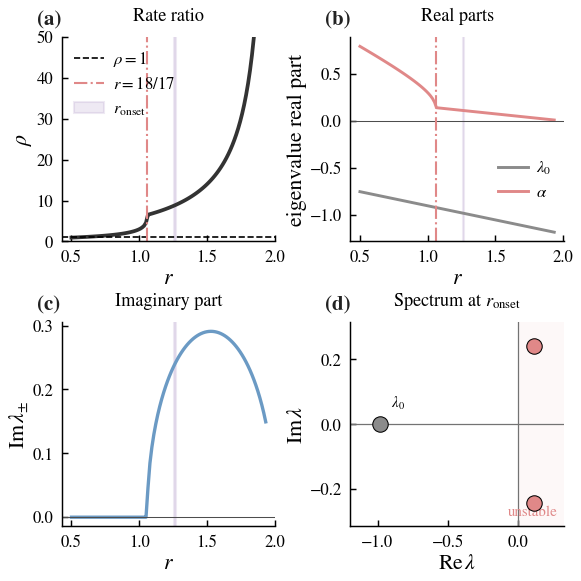

In [3]:
TICK_FONT_SIZE = 8
AXIS_LABEL_FONT_SIZE = 7.0 * 1.5
TITLE_FONT_SIZE = 7.3 * 1.2
LEGEND_FONT_SIZE = 8
ANNOTATION_FONT_SIZE = 6.0 * 1.2
PANEL_LABEL_FONT_SIZE = 10

fig, axes = plt.subplots(2, 2, figsize=(3.8, 3.8))
for axis in axes.flat:
    axis.tick_params(axis="both", direction="in", labelsize=TICK_FONT_SIZE, pad=4.0)
    axis.xaxis.labelpad = 1.4
    axis.yaxis.labelpad = 1.4

axis = axes[0, 0]
axis.plot(ratio, rho, "-", color="0.20", lw=1.8)
axis.axhline(1.0, color="k", ls="--", lw=0.8, label=r"$\rho=1$")
axis.axvline(r_split, color=C["red"], ls="-.", lw=1.0, label=r"$r=18/17$")
axis.axvspan(r_onset_lo, r_onset_hi, alpha=0.18, color=C["purple"],
             label=r"$r_{\rm onset}$")
axis.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$\rho$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title("Rate ratio", fontsize=TITLE_FONT_SIZE, pad=8.0)
axis.set_ylim(0, min(rho.max() * 1.1, 50))
axis.legend(loc="upper left", fontsize=LEGEND_FONT_SIZE, framealpha=0.0,
            facecolor="none", edgecolor="none")

axis = axes[0, 1]
axis.plot(ratio, lambda_contracting, "-", color=C["gray"], lw=1.4,
          label=r"$\lambda_{0}$")
axis.plot(ratio, lambda_expanding_real, "-", color=C["red"], lw=1.4,
          label=r"$\alpha$")
axis.axhline(0, color="0.3", lw=0.5)
axis.axvline(r_split, color=C["red"], ls="-.", lw=1.0)
axis.axvspan(r_onset_lo, r_onset_hi, alpha=0.18, color=C["purple"])
axis.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel("eigenvalue real part", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title("Real parts", fontsize=TITLE_FONT_SIZE, pad=8.0)
axis.legend(loc="center right", bbox_to_anchor=(1, 0.30), fontsize=LEGEND_FONT_SIZE,
            framealpha=0.0, facecolor="none", edgecolor="none")

axis = axes[1, 0]
axis.plot(ratio, lambda_spiral_imag_abs, "-", color=C["blue"], lw=1.6)
axis.axhline(0, color="0.3", lw=0.5)
axis.axvspan(r_onset_lo, r_onset_hi, alpha=0.18, color=C["purple"])
axis.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$\mathrm{Im}\,\lambda_{\pm}$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title("Imaginary part", fontsize=TITLE_FONT_SIZE, pad=8.0)

axis = axes[1, 1]
real_parts = eigenvalues_onset.real
imaginary_parts = eigenvalues_onset.imag
xpad = 0.15 * (real_parts.max() - real_parts.min()) + 0.05
ypad = 0.25 * (np.abs(imaginary_parts).max() + 0.05)
axis.axhline(0, color="0.45", lw=0.6)
axis.axvline(0, color="0.45", lw=0.6)
axis.axvspan(0, real_parts.max() + xpad, color=C["red"], alpha=0.06, lw=0)
for eigenvalue in eigenvalues_onset:
    unstable = eigenvalue.real > 1.0e-9
    axis.scatter(
        eigenvalue.real, eigenvalue.imag, s=55,
        color=C["red"] if unstable else C["gray"],
        edgecolor="black", linewidth=0.5, zorder=5,
    )
axis.annotate(
    r"$\lambda_{0}$", xy=(lambda_contracting[np.argmin(np.abs(ratio - r_onset))], 0),
    xytext=(5, 8), textcoords="offset points", fontsize=ANNOTATION_FONT_SIZE,
)
axis.set_xlim(real_parts.min() - xpad, real_parts.max() + xpad)
axis.set_ylim(imaginary_parts.min() - ypad, imaginary_parts.max() + ypad)
axis.text(
    0.97, 0.04, "unstable", transform=axis.transAxes,
    ha="right", va="bottom", fontsize=ANNOTATION_FONT_SIZE, color=C["red"],
)
axis.set_xlabel(r"$\mathrm{Re}\,\lambda$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$\mathrm{Im}\,\lambda$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(r"Spectrum at $r_{\rm onset}$", fontsize=TITLE_FONT_SIZE, pad=8.0)

for panel, axis in enumerate(axes.flat):
    panel_label(axis, f"({chr(97 + panel)})", fontsize=PANEL_LABEL_FONT_SIZE)

fig.tight_layout(pad=0.10, w_pad=0.08)
fig.savefig(OUTPUT)
plt.show()